---

# Tugas Besar 2 IF3170 Inteligensi Artifisial


---

## Group 12

- Muhammad Ashkar (13524007)
- Tengku Naufal Saqib (13524012)
- Rhenaldy Cahyadi Putra (13524039)
- Fayyaz Akmal Lauda (13524076)
- Muhammad Faiz Alfada Dharma (13524097)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

Pembatalan pemesanan membuat kamar kosong yang seharusnya bisa terjual ke tamu lain. Memprediksi pembatalan sejak dini membantu penginapan merencanakan overbooking, mengirim pengingat, dan menyusun kebijakan pembatalan yang tepat.

## Aim

Membangun model klasifikasi biner yang memprediksi apakah suatu pemesanan dibatalkan (is_canceled = 1) atau tidak (0). Kelima algoritma (KNN, DTL, Logistic Regression, SVM, Naive Bayes) diimplementasikan from scratch, lalu dibandingkan dengan scikit-learn.

## Metric

*To be written by the group.*

## Dataset

*To be written by the group.*

## Approach

*To be written by the group.*

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [205]:
%pip install -q numpy pandas

## Import Libraries

Every import of the notebook is kept in this cell.

In [206]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer


## Settings

Paths and shared constants are kept in this class.

In [207]:
class Settings:
    SEED       = 42
    DATA_DIR   = Path('data')
    OUTPUT_DIR = Path('output')

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [208]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [209]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [210]:
# Write your code here
print("=====================")
print("Train Dataset")
print("=====================")
print(f"Train Dataset: {train_df.shape}")
display(train_df.describe())
display(train_df.dtypes.to_frame(name="Data Type"))

print("\n=====================")
print("Test Dataset")
print("=====================")
print(f"Test Dataset: {test_df.shape}")
display(test_df.describe())
display(test_df.dtypes.to_frame(name="Data Type"))


Train Dataset
Train Dataset: (27373, 19)


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
count,26564.000000,24338.000000,27373.000000,27373.000000,26291.000000,26250.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,27373.000000,2.533500e+04,24873.000000,27373.000000
mean,1.845242,0.117388,0.814854,2.206517,0.030200,85.379429,2023.820115,7.399664,15.537537,0.025171,0.021883,0.144887,1.716980e+06,0.666948,0.327659
std,0.517974,0.425761,0.875146,1.421603,0.171142,85.969638,0.384099,3.074788,8.773321,0.156646,0.356353,1.693652,5.879368e+05,0.798363,0.469368
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2023.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2024.000000,5.000000,8.000000,0.000000,0.000000,0.000000,1.338000e+06,0.000000,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,58.000000,2024.000000,8.000000,16.000000,0.000000,0.000000,0.000000,1.644000e+06,0.000000,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,126.000000,2024.000000,10.000000,23.000000,0.000000,0.000000,0.000000,2.019000e+06,1.000000,1.000000
max,4.000000,10.000000,7.000000,17.000000,1.000000,448.000000,2024.000000,12.000000,31.000000,1.000000,13.000000,58.000000,9.165000e+06,5.000000,1.000000


,Data Type
id,object
num_adults,float64
num_children,float64
weekend_nights,int64
weekday_nights,int64
meal_package,object
needs_parking,float64
room_category,object
days_before_arrival,float64
arrival_year,int64



Test Dataset
Test Dataset: (6844, 18)


,num_adults,num_children,weekend_nights,weekday_nights,needs_parking,days_before_arrival,arrival_year,arrival_month,arrival_day,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests
count,6664.000000,6097.000000,6844.000000,6844.000000,6597.000000,6554.000000,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000,6844.000000,6.304000e+03,6251.000000
mean,1.844088,0.119567,0.796610,2.205435,0.033500,85.365426,2023.818235,7.401812,15.702659,0.027323,0.031414,0.181911,1.714169e+06,0.670613
std,0.519615,0.422822,0.858793,1.379860,0.179952,85.989244,0.385679,3.050240,8.681514,0.163035,0.444205,1.917124,5.712354e+05,0.792443
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,2023.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.000000e+00,0.000000
25%,2.000000,0.000000,0.000000,1.000000,0.000000,17.000000,2024.000000,5.000000,8.000000,0.000000,0.000000,0.000000,1.340000e+06,0.000000
50%,2.000000,0.000000,1.000000,2.000000,0.000000,57.000000,2024.000000,8.000000,16.000000,0.000000,0.000000,0.000000,1.643000e+06,0.000000
75%,2.000000,0.000000,2.000000,3.000000,0.000000,125.000000,2024.000000,10.000000,23.000000,0.000000,0.000000,0.000000,2.010250e+06,1.000000
max,4.000000,3.000000,6.000000,17.000000,1.000000,443.000000,2024.000000,12.000000,31.000000,1.000000,13.000000,53.000000,5.700000e+06,5.000000


,Data Type
id,object
num_adults,float64
num_children,float64
weekend_nights,int64
weekday_nights,int64
meal_package,object
needs_parking,float64
room_category,object
days_before_arrival,float64
arrival_year,int64


## Explore Data

This part covers distributions and relationships between attributes.


Distribusi Data Target

is_canceled
0    18404
1     8969
Name: count, dtype: int64


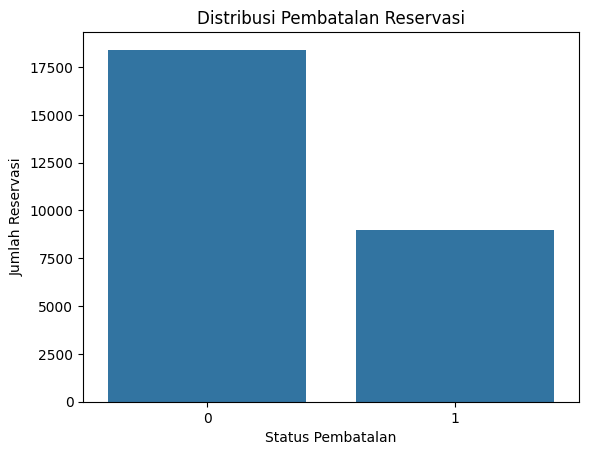


Distribusi Data Numerik



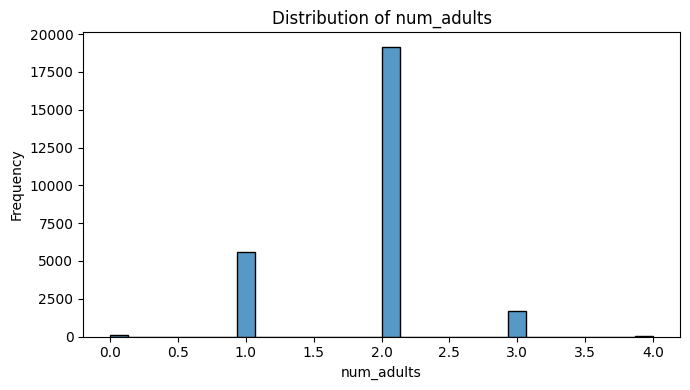

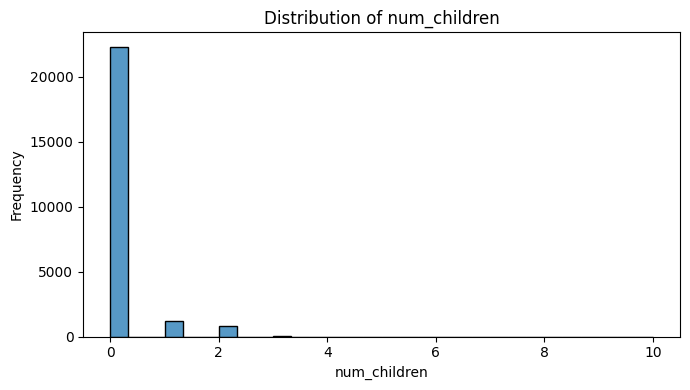

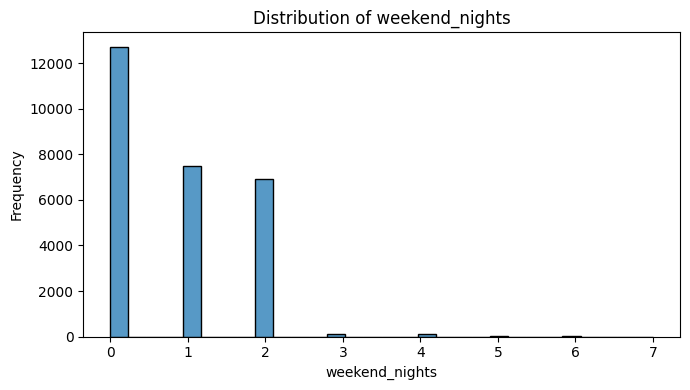

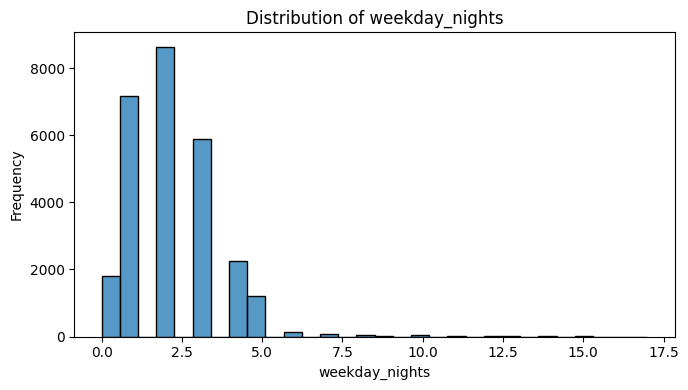

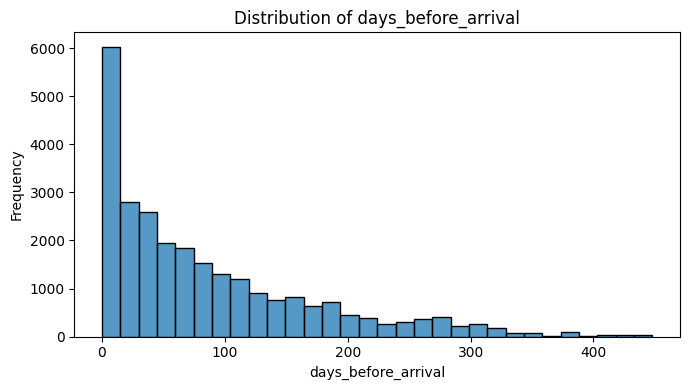

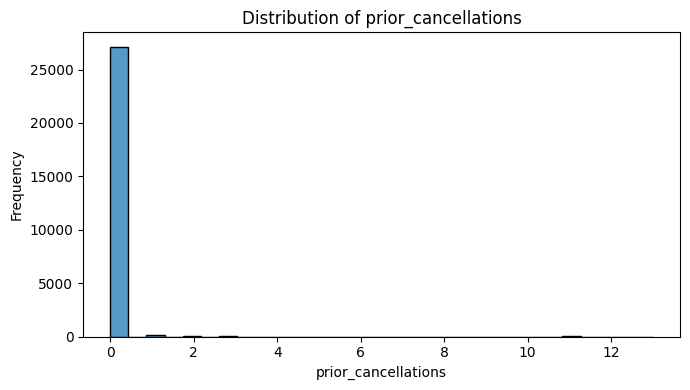

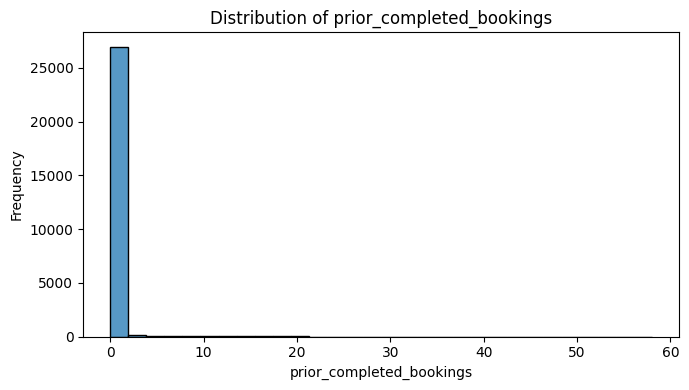

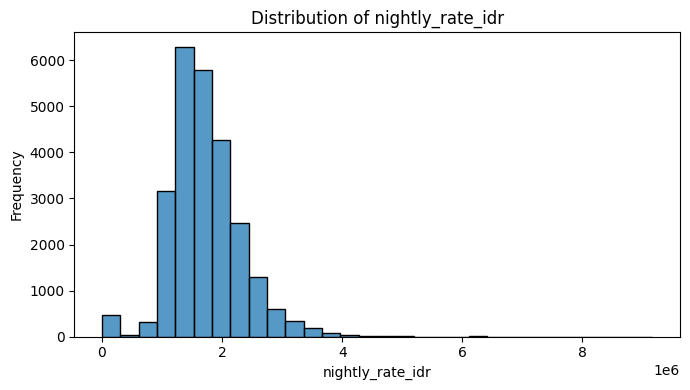

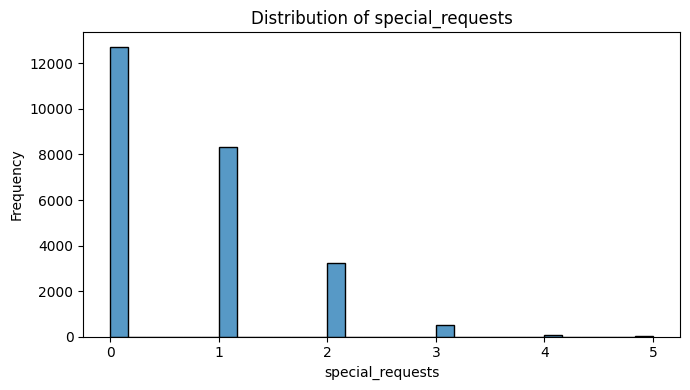


Distribusi Data Kategorikal



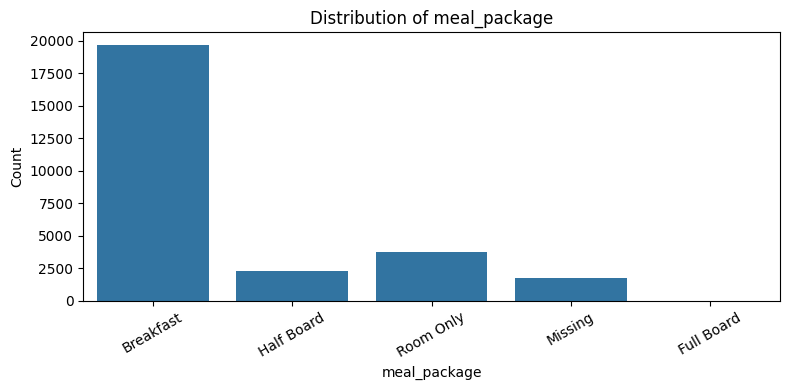

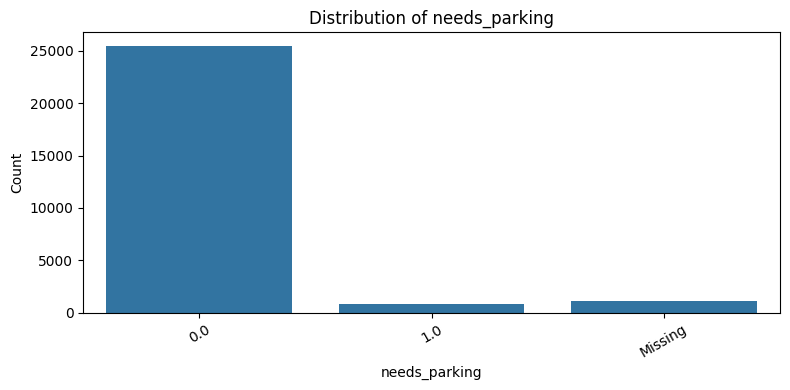

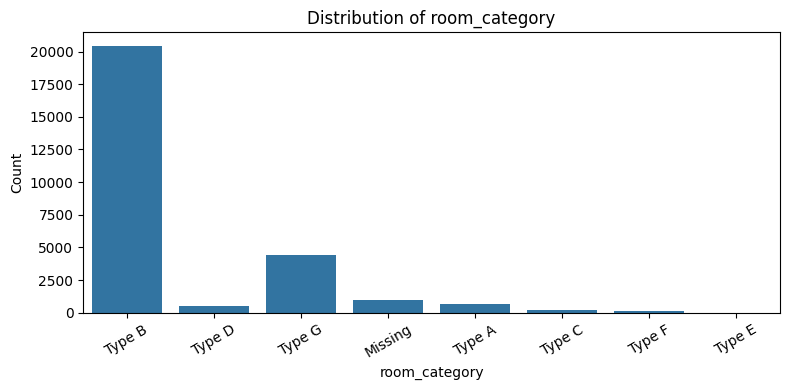

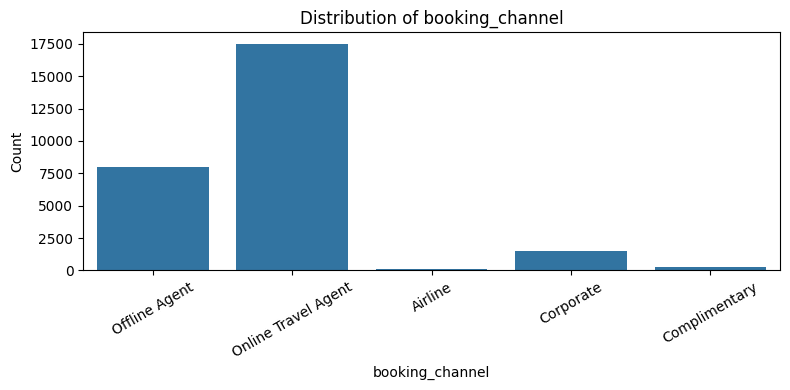

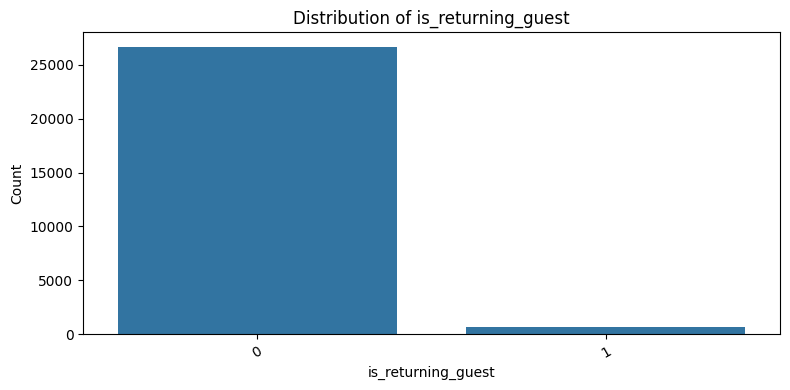


Distribusi Data Tanggal



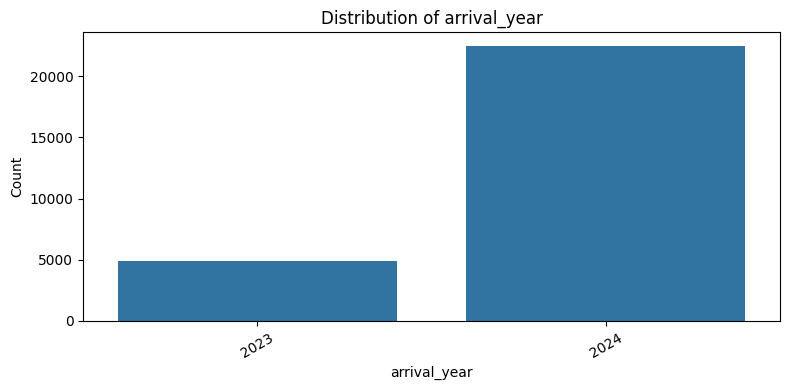

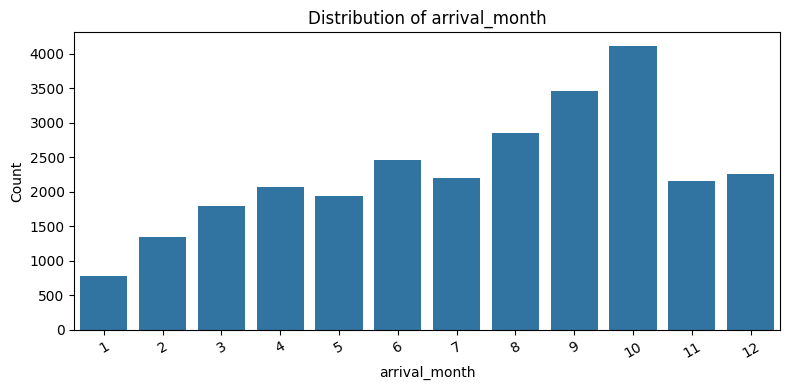

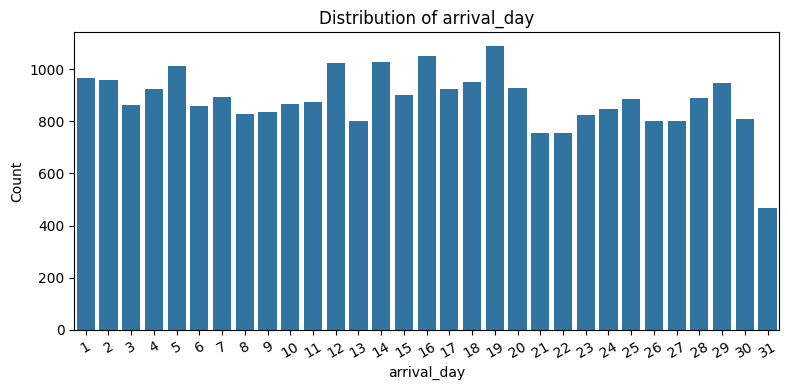


Hubungan Data Numerik dengan Target



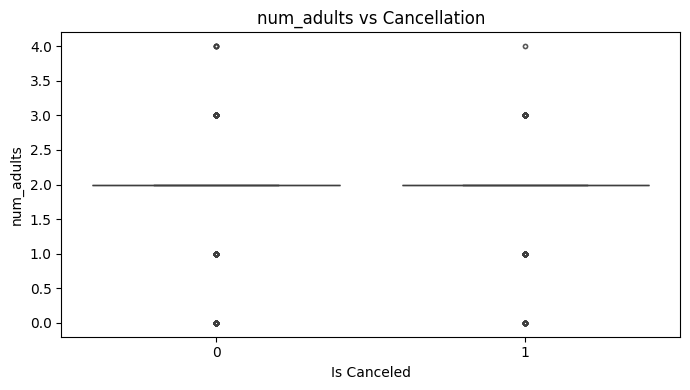

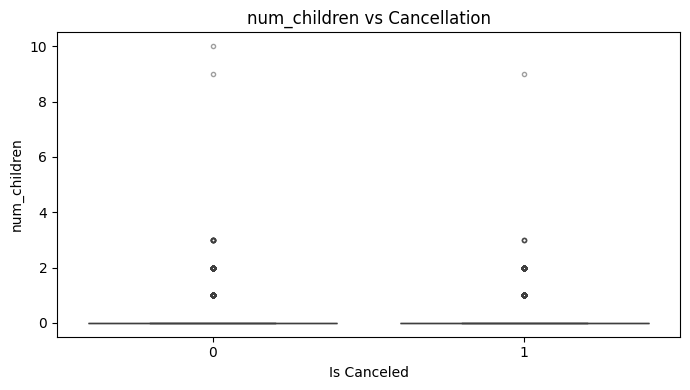

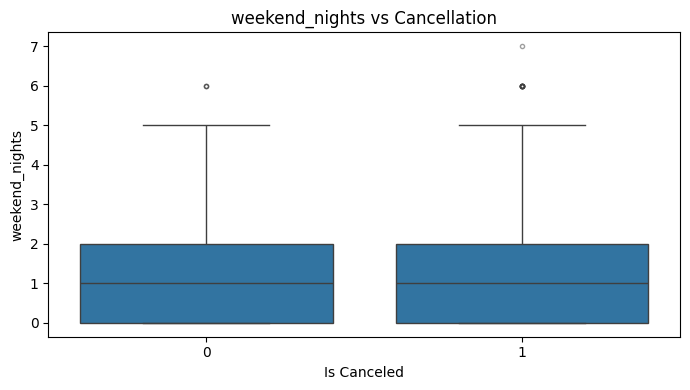

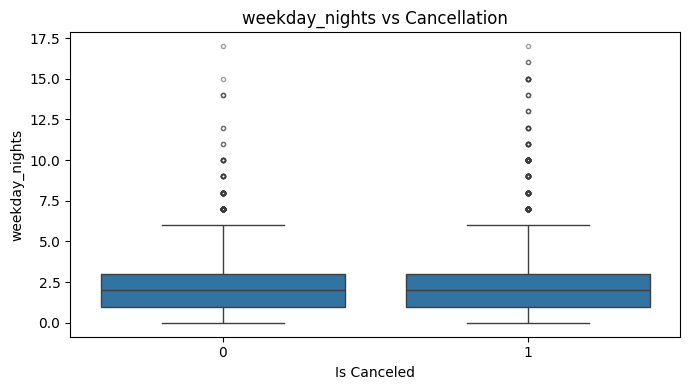

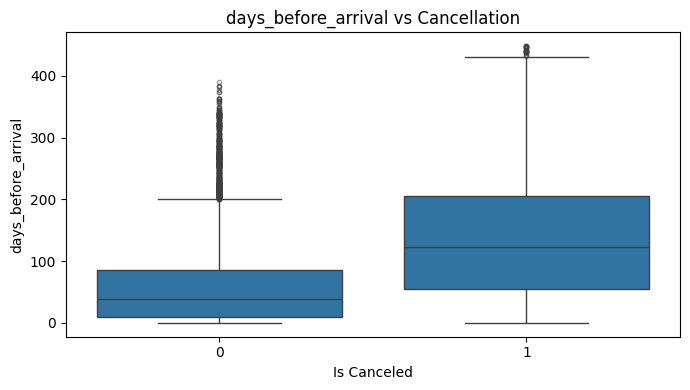

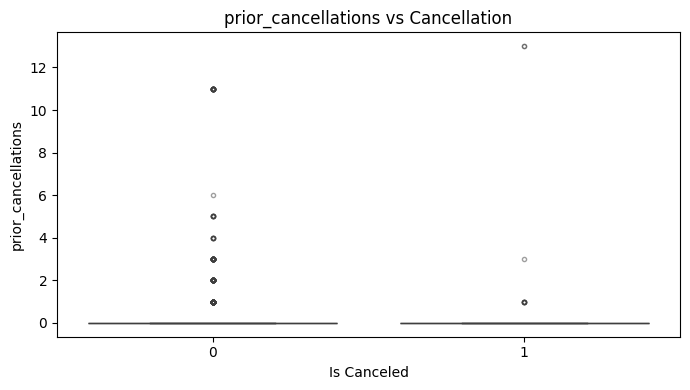

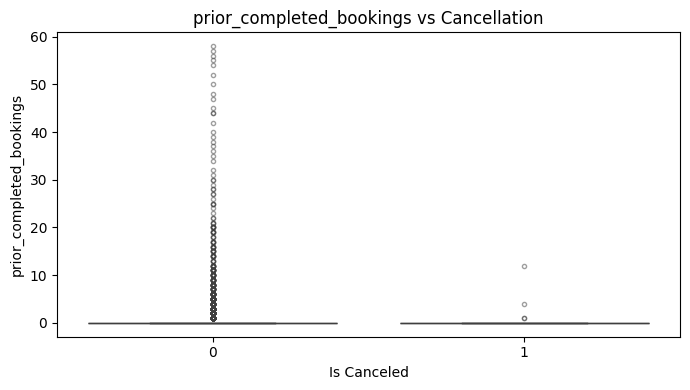

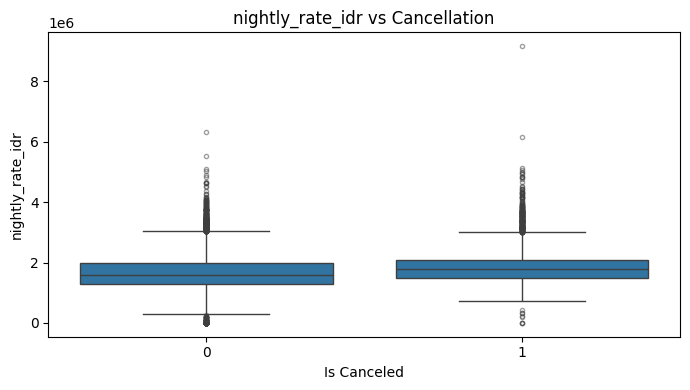

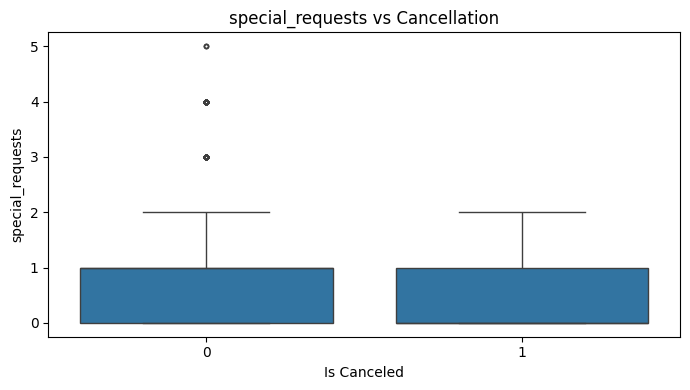


Hubungan Data Kategorikal dengan Target


Cancellation Rate by meal_package
meal_package
Breakfast     31.143788
Full Board    25.000000
Half Board    45.941124
Room Only     33.800162
NaN           31.931818
Name: is_canceled, dtype: float64


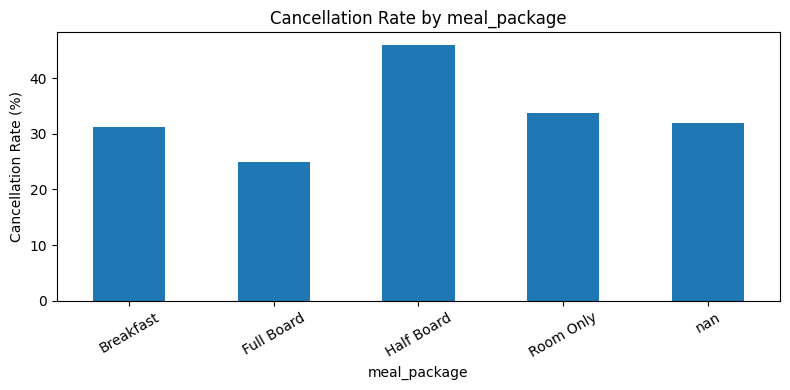


Cancellation Rate by needs_parking
needs_parking
0.0    33.537279
1.0    10.075567
NaN    31.238447
Name: is_canceled, dtype: float64


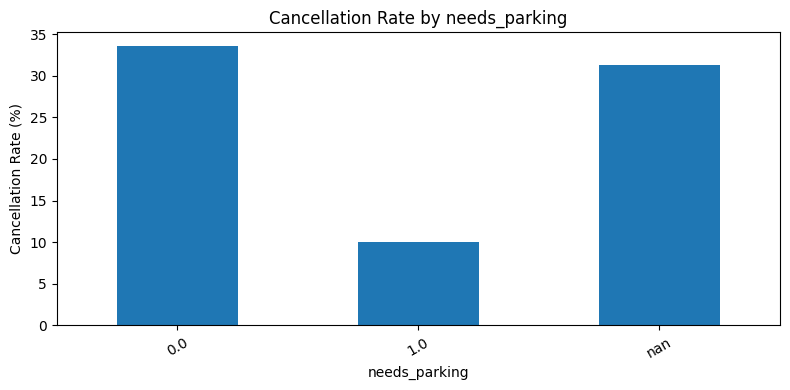


Cancellation Rate by room_category
room_category
Type A    42.632332
Type B    32.141634
Type C    24.867725
Type D    32.879377
Type E    28.571429
Type F    24.369748
Type G    34.190173
NaN       34.830339
Name: is_canceled, dtype: float64


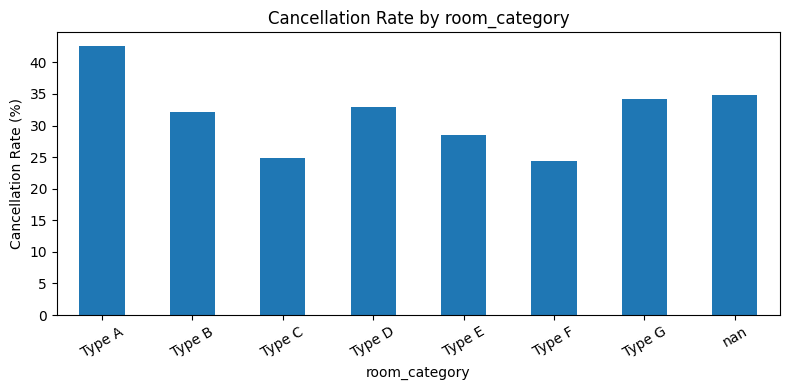


Cancellation Rate by booking_channel
booking_channel
Airline                30.681818
Complimentary           0.000000
Corporate              11.500330
Offline Agent          30.150754
Online Travel Agent    36.365713
Name: is_canceled, dtype: float64


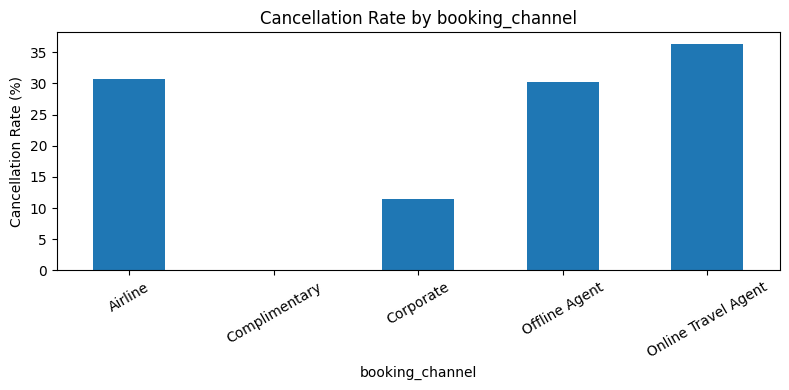


Cancellation Rate by is_returning_guest
is_returning_guest
0    33.574427
1     1.451379
Name: is_canceled, dtype: float64


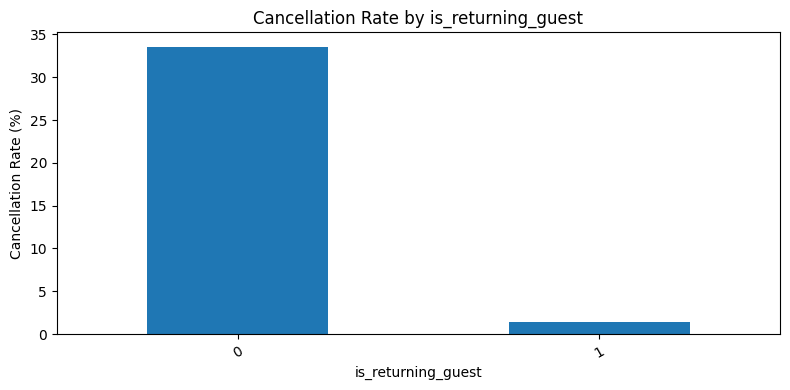


Hubungan Data Tanggal dengan Target


Cancellation Rate by arrival_year
arrival_year
2023    14.744110
2024    36.718785
Name: is_canceled, dtype: float64


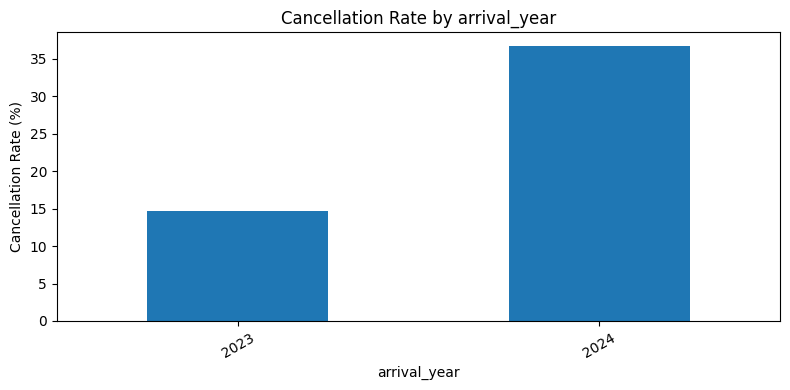


Cancellation Rate by arrival_month
arrival_month
1      2.574003
2     25.598802
3     29.843225
4     36.495644
5     37.002584
6     40.739236
7     44.813467
8     38.867394
9     33.805668
10    35.811799
11    27.790644
12    12.127943
Name: is_canceled, dtype: float64


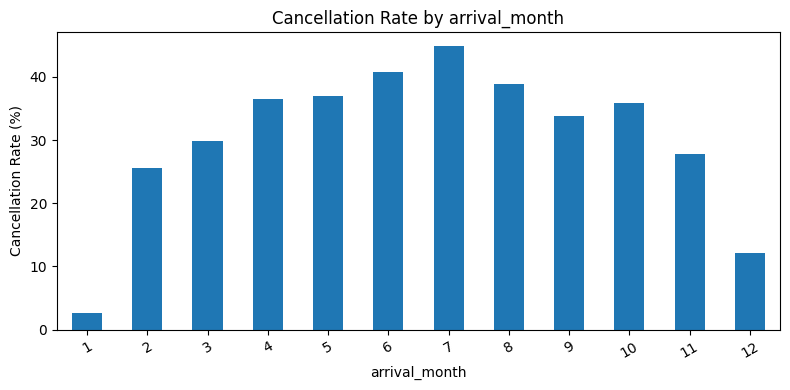


Cancellation Rate by arrival_day
arrival_day
1     28.082902
2     32.362123
3     40.672074
4     27.164502
5     31.854043
6     32.634033
7     28.491620
8     29.504232
9     27.153110
10    30.369515
11    38.628571
12    32.195122
13    31.631382
14    36.964981
15    32.777778
16    39.010466
17    29.144095
18    33.543638
19    30.330882
20    31.142241
21    33.554377
22    31.746032
23    35.714286
24    31.684335
25    38.939052
26    30.635118
27    26.807980
28    36.853933
29    36.919831
30    32.799014
31    36.830835
Name: is_canceled, dtype: float64


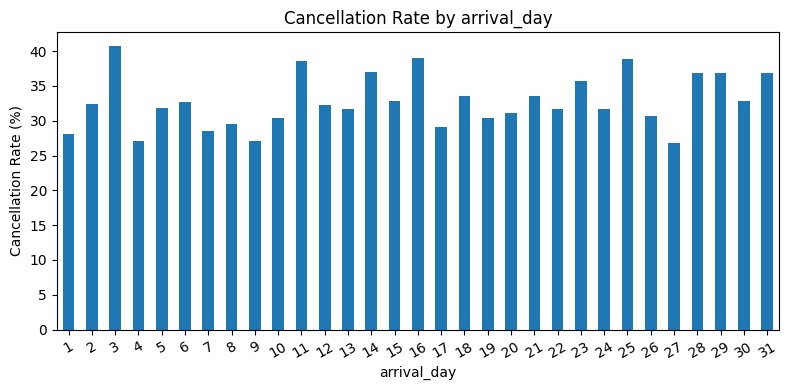


Hubungan Antaratribut Numerik dengan Heatmap



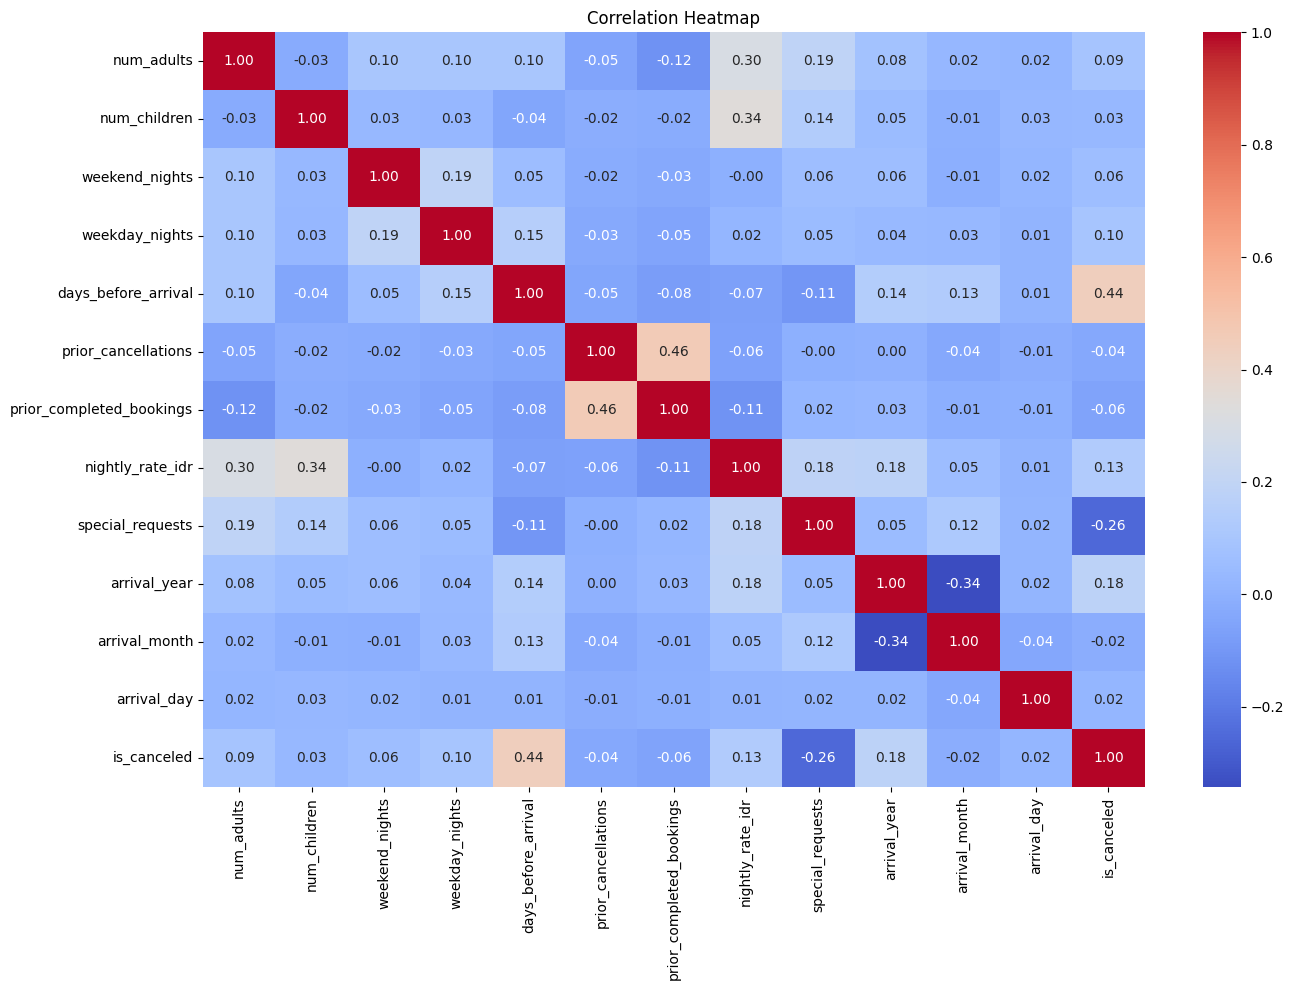

In [211]:
# ==========================================
# EXPLORE DATA
# ==========================================

# Identify all the columns
# Numerical Columns
numerical_cols = [
    "num_adults",
    "num_children",
    "weekend_nights",
    "weekday_nights",
    "days_before_arrival",
    "prior_cancellations",
    "prior_completed_bookings",
    "nightly_rate_idr",
    "special_requests"
]

# Categorical Columns
categorical_cols = [
    "meal_package",
    "needs_parking",
    "room_category",
    "booking_channel",
    "is_returning_guest"
]

# Date Columns
date_cols = [
    "arrival_year",
    "arrival_month",
    "arrival_day"
]

# Target Columns
target_cols = [
    "is_canceled"
]

# ==========================================
# DISTRIBUSI DATA TARGET
# ==========================================

print("\n=============================================")
print("Distribusi Data Target")
print("=============================================\n")

print(train_df["is_canceled"].value_counts())

sns.countplot(data=train_df, x="is_canceled")
plt.title("Distribusi Pembatalan Reservasi")
plt.xlabel("Status Pembatalan")
plt.ylabel("Jumlah Reservasi")
plt.show()

# ==========================================
# DISTRIBUSI DATA NUMERIK
# ==========================================

print("\n=============================================")
print("Distribusi Data Numerik")
print("=============================================\n")

for col in numerical_cols:
    plt.figure(figsize=(7, 4))
    sns.histplot(data=train_df, x=col, bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.tight_layout()
    plt.show()

# ==========================================
# DISTRIBUSI DATA KATEGORIKAL
# ==========================================

print("\n=============================================")
print("Distribusi Data Kategorikal")
print("=============================================\n")

for col in categorical_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(x=train_df[col].fillna("Missing").astype(str))
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

# ==========================================
# DISTRIBUSI DATA TANGGAL
# ==========================================

print("\n=============================================")
print("Distribusi Data Tanggal")
print("=============================================\n")

for col in date_cols:
    plt.figure(figsize=(8, 4))
    sns.countplot(data=train_df, x=col)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

# ==========================================
# HUBUNGAN DATA NUMERIK DENGAN TARGET
# ==========================================

print("\n=============================================")
print("Hubungan Data Numerik dengan Target")
print("=============================================\n")

for col in numerical_cols:
    plt.figure(figsize=(7, 4))

    sns.boxplot(
        data=train_df,
        x="is_canceled",
        y=col,
        showfliers=True,
        flierprops={
            "marker": "o",
            "markersize": 3,
            "alpha": 0.5
        }
    )

    plt.title(f"{col} vs Cancellation")
    plt.xlabel("Is Canceled")
    plt.ylabel(col)
    plt.tight_layout()
    plt.show()

# ==========================================
# HUBUNGAN DATA KATEGORIKAL DENGAN TARGET
# ==========================================

print("\n=============================================")
print("Hubungan Data Kategorikal dengan Target")
print("=============================================\n")

for col in categorical_cols:

    # Menghitung persentase pembatalan setiap kategori
    cancel_rate = (train_df.groupby(col, dropna=False)["is_canceled"] .mean() * 100)

    print(f"\nCancellation Rate by {col}")
    print(cancel_rate)

    plt.figure(figsize=(8, 4))
    cancel_rate.plot(kind="bar")

    plt.title(f"Cancellation Rate by {col}")
    plt.xlabel(col)
    plt.ylabel("Cancellation Rate (%)")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

# ==========================================
# HUBUNGAN DATA TANGGAL DENGAN TARGET
# ==========================================

print("\n=============================================")
print("Hubungan Data Tanggal dengan Target")
print("=============================================\n")

for col in date_cols:
    # Menghitung persentase pembatalan
    cancel_rate = (train_df.groupby(col)["is_canceled"] .mean() * 100)

    print(f"\nCancellation Rate by {col}")
    print(cancel_rate)

    plt.figure(figsize=(8, 4))
    cancel_rate.plot(kind="bar")

    plt.title(f"Cancellation Rate by {col}")
    plt.xlabel(col)
    plt.ylabel("Cancellation Rate (%)")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

# ==========================================
# KORELASI ANTARATRIBUT NUMERIK
# ==========================================

print("\n=============================================")
print("Hubungan Antaratribut Numerik dengan Heatmap")
print("=============================================\n")

# Mengambil fitur numerik, tanggal, dan target
corr_cols = numerical_cols + date_cols + target_cols

# Menghitung korelasi
correlation = train_df[corr_cols].corr()

plt.figure(figsize=(14, 10))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [212]:
# ==========================================
# VERIFY DATA QUALITY
# ==========================================

# Memeriksa missing values pada train dan test
print("\n=============================================")
print("Missing Values")
print("=============================================\n")

for nama, data in [("Train", train_df), ("Test", test_df)]:
    # Ambil jumlah dan persentase data yg missing
    missing = data.isnull().sum()
    missing_percent = data.isnull().mean() * 100

    missing_table = pd.DataFrame({
        'Jumlah Kosong': missing,
        'Persentase (%)': missing_percent.round(2)
    })

    print(f"\nMissing Values - {nama}")
    display(missing_table[missing_table['Jumlah Kosong'] > 0])

# Memeriksa data-data yangduplikat
print("\n=============================================")
print("Duplicate Data")
print("=============================================\n")

for nama, data in [("Train", train_df), ("Test", test_df)]:
    print(f"{nama} - Baris duplikat: {data.duplicated().sum()}")
    print(f"{nama} - ID duplikat: {data['id'].duplicated().sum()}")
    print(f"{nama} - Baris sama tanpa ID: {data.drop(columns='id').duplicated().sum()}")


# 3. Memeriksa konsistensi tipe data dan nilai kategori
print("\n=============================================")
print("Data Consistency")
print("=============================================\n")

# Memeriksa tipe data seluruh kolom Train dan Test
print("Perbandingan Tipe Data Train dan Test:")

dtype_table = pd.DataFrame({
    "Train": train_df.dtypes.astype(str),
    "Test": test_df.dtypes.astype(str)
})

display(dtype_table.fillna("-"))

# Memeriksa perbedaan tipe data Train dan Test
print("\nPerbedaan Tipe Data:")

for col in test_df.columns:
    if train_df[col].dtype != test_df[col].dtype:
        print(f"Tipe data berbeda pada kolom: {col}")

# Memeriksa nilai kategori pada Train dan Test
print("\n=============================================")
print("Categorical Values")
print("=============================================\n")

for nama, data in [("Train", train_df), ("Test", test_df)]:
    print(f"\nKategori pada {nama} Dataset:")

    for col in categorical_cols:
        print(f"\n{col}:")
        print(data[col].value_counts(dropna=False))


# Memeriksa kategori yang berbeda antara Train dan Test
print("\n=============================================")
print("Categorical Consistency")
print("=============================================\n")

for col in categorical_cols:
    train_categories = set(train_df[col].dropna().unique())
    test_categories = set(test_df[col].dropna().unique())

    print(f"\n{col}:")
    print("Kategori hanya di Train:", train_categories - test_categories)
    print("Kategori hanya di Test:", test_categories - train_categories)

# 4. Memeriksa nilai tidak valid
print("\n=============================================")
print("Invalid Values")
print("=============================================\n")

for nama, data in [("Train", train_df), ("Test", test_df)]:
    print(f"\n{nama}:")

    # Nilai negatif pada data numerik
    for col in data.select_dtypes(include='number').columns:
        jumlah_negatif = (data[col] < 0).sum()
        if jumlah_negatif > 0:
            print(f"Nilai negatif di {col}: {jumlah_negatif}")

    # Nilai nol yang perlu diperiksa, belum tentu salah
    print("Jumlah tamu dewasa = 0:", (data['num_adults'] == 0).sum())
    print("Harga kamar = 0:", (data['nightly_rate_idr'] == 0).sum())
    print("Lama menginap = 0:", ((data['weekend_nights'] + data['weekday_nights']) == 0).sum())

    # Kolom biner seharusnya berisi 0 atau 1
    for col in ['needs_parking', 'is_returning_guest', 'is_canceled']:
        if col in data.columns:
            salah = data[col].notna() & ~data[col].isin([0, 1])
            print(f"Nilai tidak valid pada {col}: {salah.sum()}")

    # Kombinasi tahun, bulan, dan tanggal kedatangan
    tanggal = pd.to_datetime({
        'year': data['arrival_year'],
        'month': data['arrival_month'],
        'day': data['arrival_day']
    }, errors='coerce')

    print("Tanggal kedatangan tidak valid:", tanggal.isna().sum())


Missing Values


Missing Values - Train


,Jumlah Kosong,Persentase (%)
num_adults,809,2.96
num_children,3035,11.09
meal_package,1760,6.43
needs_parking,1082,3.95
room_category,1002,3.66
days_before_arrival,1123,4.10
nightly_rate_idr,2038,7.45
special_requests,2500,9.13



Missing Values - Test


,Jumlah Kosong,Persentase (%)
num_adults,180,2.63
num_children,747,10.91
meal_package,442,6.46
needs_parking,247,3.61
room_category,242,3.54
days_before_arrival,290,4.24
nightly_rate_idr,540,7.89
special_requests,593,8.66



Duplicate Data

Train - Baris duplikat: 0
Train - ID duplikat: 0
Train - Baris sama tanpa ID: 64
Test - Baris duplikat: 0
Test - ID duplikat: 0
Test - Baris sama tanpa ID: 3

Data Consistency

Perbandingan Tipe Data Train dan Test:


,Train,Test
arrival_day,int64,int64
arrival_month,int64,int64
arrival_year,int64,int64
booking_channel,object,object
days_before_arrival,float64,float64
id,object,object
is_canceled,int64,-
is_returning_guest,int64,int64
meal_package,object,object
needs_parking,float64,float64



Perbedaan Tipe Data:

Categorical Values


Kategori pada Train Dataset:

meal_package:
meal_package
Breakfast     19654
Room Only      3713
Half Board     2242
NaN            1760
Full Board        4
Name: count, dtype: int64

needs_parking:
needs_parking
0.0    25497
NaN     1082
1.0      794
Name: count, dtype: int64

room_category:
room_category
Type B    20447
Type G     4396
NaN        1002
Type A      699
Type D      514
Type C      189
Type F      119
Type E        7
Name: count, dtype: int64

booking_channel:
booking_channel
Online Travel Agent    17511
Offline Agent           7960
Corporate               1513
Complimentary            301
Airline                   88
Name: count, dtype: int64

is_returning_guest:
is_returning_guest
0    26684
1      689
Name: count, dtype: int64

Kategori pada Test Dataset:

meal_package:
meal_package
Breakfast     4940
Room Only      918
Half Board     543
NaN            442
Full Board       1
Name: count, dtype: int64

needs_parking:
needs_p

---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [213]:
# # ==========================================
# # TRAINING AND VALIDATION SPLIT
# # ==========================================

# # Memilih fitur dan target
# selected_cols = numerical_cols + categorical_cols + date_cols

# X = train_df[selected_cols].copy()
# y = train_df["is_canceled"].copy()

# # Test Kaggle
# X_test = test_df[selected_cols].copy()

# # Membagi Train menjadi Training dan Validation
# x_train, x_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# print("Training Data  :", x_train.shape)
# print("Validation Data:", x_val.shape)
# print("Test Data    :", X_test.shape)

# ==========================================
# TRAINING AND VALIDATION SPLIT / K-FOLD
# ==========================================

from sklearn.model_selection import train_test_split, StratifiedKFold

# ==========================================
# KONFIGURASI
# ==========================================

# True  = Hold-out 80:20
# False = Stratified K-Fold
USE_SPLIT = False

# Jumlah fold untuk Cross-Validation
N_SPLITS = 5


# ==========================================
# MEMILIH FITUR DAN TARGET
# ==========================================

selected_cols = numerical_cols + categorical_cols + date_cols

X = train_df[selected_cols].copy()
y = train_df["is_canceled"].copy()

# Test Kaggle hanya untuk submission
X_test = test_df[selected_cols].copy()


# ==========================================
# STRATIFIED K-FOLD
# ==========================================

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=42
)


# ==========================================
# MEMILIH METODE VALIDASI
# ==========================================

if USE_SPLIT:

    # Hold-out Validation 80:20
    x_train, x_val, y_train, y_val = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    print("Mode: Hold-out 80:20")

else:

    # K-Fold dijalankan pada seluruh X dan y di sel KNN.
    # Fold pertama hanya digunakan untuk menjaga
    # kompatibilitas sel Data Preparation sebelumnya.

    train_idx, val_idx = next(cv.split(X, y))

    x_train = X.iloc[train_idx].copy()
    x_val = X.iloc[val_idx].copy()

    y_train = y.iloc[train_idx].copy()
    y_val = y.iloc[val_idx].copy()

    print(f"Mode: Stratified {N_SPLITS}-Fold CV")
    print("Fold pertama digunakan untuk demonstrasi Data Preparation.")
    print("KNN akan menggunakan semua fold pada seluruh X dan y.")


# ==========================================
# MENAMPILKAN HASIL
# ==========================================

print("\n=============================================")
print("Training and Validation Strategy")
print("=============================================\n")

print("Training Data  :", x_train.shape)
print("Validation Data:", x_val.shape)
print("Test Kaggle    :", X_test.shape)

Mode: Stratified 5-Fold CV
Fold pertama digunakan untuk demonstrasi Data Preparation.
KNN akan menggunakan semua fold pada seluruh X dan y.

Training and Validation Strategy

Training Data  : (21898, 17)
Validation Data: (5475, 17)
Test Kaggle    : (6844, 17)


---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

In [214]:
# ==========================================
# SELECT DATA
# ==========================================

# Memilih atribut yang digunakan sebagai fitur
selected_cols = numerical_cols + categorical_cols + date_cols

# Memisahkan fitur dan target pada Train Dataset
X_train = train_df[selected_cols].copy()
y = train_df["is_canceled"].copy()

# Memilih fitur yang sama pada Test Dataset
X_test = test_df[selected_cols].copy()

# Menampilkan hasil pemilihan data
print("\n=============================================")
print("Selected Features")
print("=============================================\n")

print("Jumlah fitur yang dipilih:", len(selected_cols))
print("\nFitur yang digunakan:")
print(selected_cols)

print("\n=============================================")
print("Selected Data Shape")
print("=============================================\n")

print("Train Features :", X.shape)
print("Train Target   :", y.shape)
print("Test Features  :", X_test.shape)

# Menampilkan data yang sudah diseleksi
print("\nSelected Train Data:")
display(X.head())

print("\nSelected Test Data:")
display(X_test.head())


Selected Features

Jumlah fitur yang dipilih: 17

Fitur yang digunakan:
['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'days_before_arrival', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests', 'meal_package', 'needs_parking', 'room_category', 'booking_channel', 'is_returning_guest', 'arrival_year', 'arrival_month', 'arrival_day']

Selected Data Shape

Train Features : (27373, 17)
Train Target   : (27373,)
Test Features  : (6844, 17)

Selected Train Data:


,num_adults,num_children,weekend_nights,weekday_nights,days_before_arrival,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,meal_package,needs_parking,room_category,booking_channel,is_returning_guest,arrival_year,arrival_month,arrival_day
0,2.0,NaN,1,2,88.0,0,0,1330000.0,0.0,Breakfast,0.0,Type B,Offline Agent,0,2024,4,3
1,2.0,0.0,2,1,120.0,0,0,NaN,0.0,Half Board,0.0,Type D,Offline Agent,0,2023,8,1
2,3.0,0.0,1,2,209.0,0,0,2099000.0,0.0,Breakfast,0.0,Type G,Online Travel Agent,0,2024,8,28
3,2.0,1.0,2,1,93.0,0,0,1693000.0,2.0,Breakfast,0.0,Type G,Online Travel Agent,0,2024,8,13
4,2.0,0.0,0,1,14.0,0,0,2010000.0,2.0,Room Only,0.0,Type B,Online Travel Agent,0,2024,9,1



Selected Test Data:


,num_adults,num_children,weekend_nights,weekday_nights,days_before_arrival,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,meal_package,needs_parking,room_category,booking_channel,is_returning_guest,arrival_year,arrival_month,arrival_day
0,2.0,0.0,0,1,217.0,0,0,1299000.0,0.0,Breakfast,0.0,Type B,Offline Agent,0,2024,8,11
1,2.0,0.0,1,2,190.0,0,0,2010000.0,0.0,Breakfast,0.0,Type B,Online Travel Agent,0,2024,6,19
2,2.0,0.0,1,2,124.0,0,0,1921000.0,1.0,Breakfast,0.0,Type B,Online Travel Agent,0,2024,5,12
3,NaN,0.0,2,4,0.0,0,0,1451000.0,0.0,Half Board,0.0,Type B,Online Travel Agent,0,2024,1,2
4,2.0,1.0,2,3,44.0,0,0,1225000.0,2.0,Breakfast,0.0,Type G,Offline Agent,0,2023,11,1


## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [215]:
# ==========================================
# MISSING VALUES
# ==========================================

# Memeriksa missing values
print("\n=============================================")
print("Missing Values")
print("=============================================\n")

for nama, data in [("Train", x_train), ("Validation", x_val), ("Test", X_test)]:
    print(f"\nMissing Values - {nama}")
    missing = data.isnull().sum()
    display(missing[missing > 0].to_frame(name="Jumlah Kosong"))


Missing Values


Missing Values - Train


,Jumlah Kosong
num_adults,653
num_children,2448
days_before_arrival,890
nightly_rate_idr,1633
special_requests,1986
meal_package,1391
needs_parking,860
room_category,806



Missing Values - Validation


,Jumlah Kosong
num_adults,156
num_children,587
days_before_arrival,233
nightly_rate_idr,405
special_requests,514
meal_package,369
needs_parking,222
room_category,196



Missing Values - Test


,Jumlah Kosong
num_adults,180
num_children,747
days_before_arrival,290
nightly_rate_idr,540
special_requests,593
meal_package,442
needs_parking,247
room_category,242


In [216]:
# Identifikasi kolom yg memiliki missing values
numeric_missing_cols = [
    "num_adults",
    "num_children",
    "days_before_arrival",
    "nightly_rate_idr",
    "special_requests"
]

categorical_missing_cols = [
    "meal_package",
    "room_category"
]

binary_missing_cols = [ # Data yang nilainya hanya 0/1
    "needs_parking"
]

# Membuat imputer
num_imputer = SimpleImputer(strategy="median")
cat_imputer = SimpleImputer(strategy="most_frequent")
binary_imputer = SimpleImputer(strategy="most_frequent")

# Membuat salinan data
x_train_clean = x_train.copy()
x_val_clean = x_val.copy()
X_test_clean = X_test.copy()

# ==========================================
# Imputasi Training Data
# ==========================================

x_train_clean[numeric_missing_cols] = num_imputer.fit_transform(x_train[numeric_missing_cols])
x_train_clean[categorical_missing_cols] = cat_imputer.fit_transform(x_train[categorical_missing_cols])
x_train_clean[binary_missing_cols] = binary_imputer.fit_transform(x_train[binary_missing_cols])

# ==========================================
# Imputasi Validation dan Test
# ==========================================

for data_clean in [x_val_clean, X_test_clean]:
    data_clean[numeric_missing_cols] = num_imputer.transform(data_clean[numeric_missing_cols])
    data_clean[categorical_missing_cols] = cat_imputer.transform(data_clean[categorical_missing_cols])
    data_clean[binary_missing_cols] = binary_imputer.transform(data_clean[binary_missing_cols])

# ==========================================
# Validate hasil imputasi
# ==========================================

print("\n=============================================")
print("Validate imputation")
print("=============================================\n")

for nama, data in [("Train", x_train_clean), ("Validation", x_val_clean), ("Test", X_test_clean)]:
    print(f"{nama} - Total Missing Values: {data.isnull().sum().sum()}")


Validate imputation

Train - Total Missing Values: 0
Validation - Total Missing Values: 0
Test - Total Missing Values: 0


### Duplicates

This part covers repeated records.

In [217]:
# ==========================================
# DUPLICATE DATA
# ==========================================

print("\n=============================================")
print("Duplicate Data pada Training Data")
print("=============================================\n")

# Memeriksa duplikat pada data yang sudah dibersihkan
duplicate_train = x_train_clean.duplicated().sum()
print("Jumlah data duplikat berdasarkan fitur:", duplicate_train)

# Memeriksa duplikat berdasarkan fitur dan target
train_check = x_train_clean.copy()
train_check["is_canceled"] = y_train

duplicate_full = train_check.duplicated().sum()
print("Jumlah data duplikat berdasarkan fitur dan target:", duplicate_full)

# Menampilkan data duplikat
if duplicate_full > 0:
    print("\nData yang duplikat:")
    display(train_check[train_check.duplicated(keep=False)].head(10))
else:
    print("\nTidak ditemukan data duplikat.")



Duplicate Data pada Training Data

Jumlah data duplikat berdasarkan fitur: 104
Jumlah data duplikat berdasarkan fitur dan target: 102

Data yang duplikat:


,num_adults,num_children,weekend_nights,weekday_nights,days_before_arrival,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,meal_package,needs_parking,room_category,booking_channel,is_returning_guest,arrival_year,arrival_month,arrival_day,is_canceled
320,2.0,0.0,0,2,77.0,0,0,1763000.0,0.0,Half Board,0.0,Type B,Offline Agent,0,2023,9,18,0
932,2.0,0.0,0,3,38.0,0,0,1645000.0,0.0,Breakfast,0.0,Type B,Offline Agent,0,2024,10,12,0
967,2.0,0.0,0,2,107.0,0,0,1645000.0,0.0,Half Board,0.0,Type B,Offline Agent,0,2023,10,16,0
1003,2.0,0.0,0,1,39.0,0,0,0.0,0.0,Breakfast,0.0,Type B,Online Travel Agent,0,2023,10,23,0
1109,1.0,0.0,0,3,58.0,0,0,1645000.0,0.0,Breakfast,0.0,Type B,Offline Agent,0,2024,6,13,0
1134,2.0,0.0,1,1,184.0,0,0,1645000.0,1.0,Breakfast,0.0,Type B,Offline Agent,0,2024,5,1,0
1317,1.0,0.0,2,1,6.0,0,0,1645000.0,0.0,Breakfast,0.0,Type B,Offline Agent,0,2024,2,28,1
1557,2.0,0.0,0,1,448.0,0,0,1645000.0,0.0,Breakfast,0.0,Type B,Offline Agent,0,2024,4,28,1
1626,1.0,0.0,0,3,155.0,0,0,1645000.0,0.0,Breakfast,0.0,Type B,Offline Agent,0,2024,1,19,0
1733,2.0,0.0,0,3,33.0,0,0,1645000.0,0.0,Breakfast,0.0,Type B,Offline Agent,0,2024,10,12,0


### Outliers

This part covers values far from the rest of the data.

In [218]:
# ==========================================
# OUTLIERS
# ==========================================

# Menghitung outlier dengan IQR
print("\n=============================================")
print("Outlier Detection (IQR)")
print("=============================================\n")

X_outlier = x_train_clean.copy()

for col in numerical_cols:
    Q1 = X_outlier[col].quantile(0.25)
    Q3 = X_outlier[col].quantile(0.75)
    IQR = Q3 - Q1

    if IQR > 0:
        batas_bawah = Q1 - 1.5 * IQR
        batas_atas = Q3 + 1.5 * IQR

        jumlah_outlier = ((X_outlier[col] < batas_bawah) | (X_outlier[col] > batas_atas)).sum()
        print(f"{col}: {jumlah_outlier} outlier")

    else:
        # Semua nilai yang berbeda dari nilai tersebut bisa ditandai sebagai outlier, meskipun sebenarnya valid
        print(f"{col}: IQR = 0")


Outlier Detection (IQR)

num_adults: IQR = 0
num_children: IQR = 0
weekend_nights: 14 outlier
weekday_nights: 206 outlier
days_before_arrival: 887 outlier
prior_cancellations: IQR = 0
prior_completed_bookings: IQR = 0
nightly_rate_idr: 1114 outlier
special_requests: 448 outlier


### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [237]:
# Write your code here


## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

This part covers new attributes derived from existing ones.

In [220]:
# ==========================================
# ATTRIBUTE CONSTRUCTION
# ==========================================

# Membuat atribut baru dari fitur yang sudah ada
def add_features(data):
    hasil = data.copy()

    # Total malam menginap
    hasil['total_nights'] = hasil['weekend_nights'] + hasil['weekday_nights']

    # Total jumlah tamu
    hasil['total_guests'] = hasil['num_adults'] + hasil['num_children']

    return hasil

# Menambahkan atribut baru pada Train, Validation, dan Test
x_train_constructed = add_features(x_train_clean)
x_val_constructed = add_features(x_val_clean)
X_test_constructed = add_features(X_test_clean)

# Menampilkan hasil atribut baru
print("\n=============================================")
print("Attribute Construction")
print("=============================================\n")

print("Contoh Atribut Baru pada Training Data:")
display(x_train_constructed[['total_nights', 'total_guests']].head())

print("\nJumlah Fitur Sebelum:", x_train_clean.shape[1])
print("Jumlah Fitur Sesudah:", x_train_constructed.shape[1])


Attribute Construction

Contoh Atribut Baru pada Training Data:


,total_nights,total_guests
0,3,2.0
1,3,2.0
2,3,3.0
3,3,3.0
4,1,2.0



Jumlah Fitur Sebelum: 17
Jumlah Fitur Sesudah: 19


### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

In [221]:
# ==========================================
# FEATURE SCALING
# ==========================================

from sklearn.preprocessing import RobustScaler

# Fitur numerik yang akan discaling
final_num_features = numerical_cols + date_cols + [
    "total_nights",
    "total_guests"
]

# Attribute Construction
x_train_constructed = add_features(x_train_clean)
x_val_constructed = add_features(x_val_clean)
X_test_constructed = add_features(X_test_clean)

# Membuat salinan data
x_train_scaled = x_train_constructed.copy()
x_val_scaled = x_val_constructed.copy()
X_test_scaled = X_test_constructed.copy()

# StandardScaler
scaler = RobustScaler()

# Training
x_train_scaled[final_num_features] = scaler.fit_transform(x_train_constructed[final_num_features])

# Validation
x_val_scaled[final_num_features] = scaler.transform(x_val_constructed[final_num_features])

# Test
X_test_scaled[final_num_features] = scaler.transform(X_test_constructed[final_num_features])

# Menampilkan hasil
print("Data Sebelum Feature Scaling:")
display(x_train_constructed[final_num_features].head())

print("\nData Setelah Feature Scaling:")
display(x_train_scaled[final_num_features].head())

Data Sebelum Feature Scaling:


,num_adults,num_children,weekend_nights,weekday_nights,days_before_arrival,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,arrival_year,arrival_month,arrival_day,total_nights,total_guests
0,2.0,0.0,1,2,88.0,0,0,1330000.0,0.0,2024,4,3,3,2.0
1,2.0,0.0,2,1,120.0,0,0,1645000.0,0.0,2023,8,1,3,2.0
2,3.0,0.0,1,2,209.0,0,0,2099000.0,0.0,2024,8,28,3,3.0
3,2.0,1.0,2,1,93.0,0,0,1693000.0,2.0,2024,8,13,3,3.0
4,2.0,0.0,0,1,14.0,0,0,2010000.0,2.0,2024,9,1,1,2.0



Data Setelah Feature Scaling:


,num_adults,num_children,weekend_nights,weekday_nights,days_before_arrival,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,arrival_year,arrival_month,arrival_day,total_nights,total_guests
0,0.0,0.0,0.0,0.0,0.288462,0.0,0.0,-0.514706,0.0,0.0,-0.8,-0.866667,0.0,0.0
1,0.0,0.0,0.5,-0.5,0.596154,0.0,0.0,0.000000,0.0,-1.0,0.0,-1.000000,0.0,0.0
2,1.0,0.0,0.0,0.0,1.451923,0.0,0.0,0.741830,0.0,0.0,0.0,0.800000,0.0,1.0
3,0.0,1.0,0.5,-0.5,0.336538,0.0,0.0,0.078431,2.0,0.0,0.0,-0.200000,0.0,1.0
4,0.0,0.0,-0.5,-0.5,-0.423077,0.0,0.0,0.596405,2.0,0.0,0.2,-1.000000,-1.0,0.0


### Encoding

This part covers the numeric representation of categorical attributes.

In [222]:
# ==========================================
# ENCODING
# ==========================================

from sklearn.preprocessing import OneHotEncoder

# Fitur kategorikal yang akan diencoding
encoding_cols = [
    "meal_package",
    "room_category",
    "booking_channel"
]

# Membuat encoder dengan one hot encoder
encoder = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

# Encoding pada Training Data
train_encoded = encoder.fit_transform(x_train_scaled[encoding_cols])

# Encoding pada Validation dan Test data
val_encoded = encoder.transform(x_val_scaled[encoding_cols])
test_encoded = encoder.transform(X_test_scaled[encoding_cols])

# Mengambil nama kolom hasil encoding
encoded_cols = encoder.get_feature_names_out(encoding_cols)

train_encoded = pd.DataFrame(train_encoded, columns=encoded_cols, index=x_train_scaled.index)
val_encoded = pd.DataFrame(val_encoded, columns=encoded_cols, index=x_val_scaled.index)
test_encoded = pd.DataFrame(test_encoded, columns=encoded_cols, index=X_test_scaled.index)

# Menggabungkan hasil encoding dengan fitur lainnya
x_train_encoded = pd.concat([x_train_scaled.drop(columns=encoding_cols), train_encoded], axis=1)
x_val_encoded = pd.concat([x_val_scaled.drop(columns=encoding_cols), val_encoded], axis=1)
X_test_encoded = pd.concat([X_test_scaled.drop(columns=encoding_cols), test_encoded], axis=1)

print("\n=============================================")
print("Encoding Results")
print("=============================================\n")

print("Training Data  :", x_train_encoded.shape)
print("Validation Data:", x_val_encoded.shape)
print("Test Data    :", X_test_encoded.shape)

print("\nHasil One-Hot Encoding:")
display(train_encoded.head())

print("\nData Training Setelah Encoding:")
display(x_train_encoded.head())

print("\nJumlah Fitur Setelah Encoding:", x_train_encoded.shape[1])


Encoding Results

Training Data  : (21898, 32)
Validation Data: (5475, 32)
Test Data    : (6844, 32)

Hasil One-Hot Encoding:


,meal_package_Breakfast,meal_package_Full Board,meal_package_Half Board,meal_package_Room Only,room_category_Type A,room_category_Type B,room_category_Type C,room_category_Type D,room_category_Type E,room_category_Type F,room_category_Type G,booking_channel_Airline,booking_channel_Complimentary,booking_channel_Corporate,booking_channel_Offline Agent,booking_channel_Online Travel Agent
0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0



Data Training Setelah Encoding:


,num_adults,num_children,weekend_nights,weekday_nights,days_before_arrival,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,needs_parking,...,room_category_Type C,room_category_Type D,room_category_Type E,room_category_Type F,room_category_Type G,booking_channel_Airline,booking_channel_Complimentary,booking_channel_Corporate,booking_channel_Offline Agent,booking_channel_Online Travel Agent
0,0.0,0.0,0.0,0.0,0.288462,0.0,0.0,-0.514706,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.0,0.0,0.5,-0.5,0.596154,0.0,0.0,0.000000,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
2,1.0,0.0,0.0,0.0,1.451923,0.0,0.0,0.741830,0.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
3,0.0,1.0,0.5,-0.5,0.336538,0.0,0.0,0.078431,2.0,0.0,...,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
4,0.0,0.0,-0.5,-0.5,-0.423077,0.0,0.0,0.596405,2.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0



Jumlah Fitur Setelah Encoding: 32


### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

In [223]:
# ==========================================
# DIMENSIONALITY REDUCTION
# ==========================================

from sklearn.decomposition import PCA

print("\n=============================================")
print("Dimensionality Reduction - PCA")
print("=============================================\n")

# Membuat PCA dengan mempertahankan 95% variansi
pca = PCA(n_components=0.95)

# Fit PCA hanya pada training
x_train_pca = pca.fit_transform(x_train_encoded)

# Transform validation dan test menggunakan PCA yang sama
x_val_pca = pca.transform(x_val_encoded)
X_test_pca = pca.transform(X_test_encoded)

# Menampilkan hasil
print("Jumlah fitur sebelum PCA:", x_train_encoded.shape[1])
print("Jumlah komponen setelah PCA:", pca.n_components_)

print("Total Explained Variance:", round(pca.explained_variance_ratio_.sum() * 100, 2), "%")

print("\nTraining Data  :", x_train_pca.shape)
print("Validation Data:", x_val_pca.shape)
print("Test Data  :", X_test_pca.shape)


Dimensionality Reduction - PCA

Jumlah fitur sebelum PCA: 32
Jumlah komponen setelah PCA: 13
Total Explained Variance: 95.28 %

Training Data  : (21898, 13)
Validation Data: (5475, 13)
Test Data  : (6844, 13)


## Class Balance

This part covers the proportion of each class in the training data.


Class Balance

Jumlah setiap kelas:
is_canceled
0    14723
1     7175
Name: count, dtype: int64

Persentase setiap kelas:
is_canceled
0    67.23
1    32.77
Name: proportion, dtype: float64


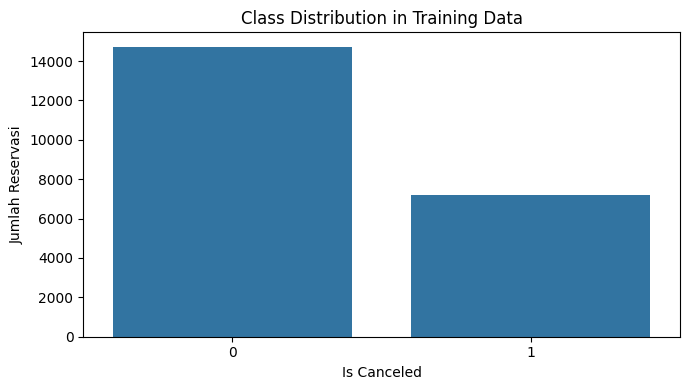

In [224]:
# ==========================================
# CLASS BALANCE
# ==========================================

print("\n=============================================")
print("Class Balance")
print("=============================================\n")

# Menghitung jumlah setiap kelas
print("Jumlah setiap kelas:")
print(y_train.value_counts())

# Menghitung persentase setiap kelas
print("\nPersentase setiap kelas:")
print((y_train.value_counts(normalize=True) * 100).round(2))

# Visualisasi distribusi kelas
plt.figure(figsize=(7, 4))

sns.countplot(x=y_train)

plt.title("Class Distribution in Training Data")
plt.xlabel("Is Canceled")
plt.ylabel("Jumlah Reservasi")
plt.tight_layout()
plt.show()

## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [225]:
# ==========================================
# FORMAT DATA
# ==========================================

import numpy as np

print("\n=============================================")
print("Format Data")
print("=============================================\n")

# Mengubah data hasil PCA menjadi matriks numerik
X_train_model = np.asarray(x_train_pca, dtype=float)
X_val_model = np.asarray(x_val_pca, dtype=float)
X_test_model = np.asarray(X_test_pca, dtype=float)

# Menyiapkan target sesuai baris training dan validation
y_train_model = y_train.loc[x_train_encoded.index].to_numpy()
y_val_model = y_val.loc[x_val_encoded.index].to_numpy()

# Memeriksa struktur data
print("Training Data  :", X_train_model.shape)
print("Validation Data:", X_val_model.shape)
print("Test Data     :", X_test_model.shape)

print("\nData Type:")
print("Train:", X_train_model.dtype)
print("Validation:", X_val_model.dtype)
print("Test:", X_test_model.dtype)


Format Data

Training Data  : (21898, 13)
Validation Data: (5475, 13)
Test Data     : (6844, 13)

Data Type:
Train: float64
Validation: float64
Test: float64


---

# Preparation Pipeline <a name="6"></a>

---

The pipeline combines the preparation steps so they run in one consistent order.

In [239]:
# ==========================================
# PREPARATION PIPELINE
# ==========================================

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
import numpy as np

print("\n=============================================")
print("Preparation Pipeline")
print("=============================================\n")

# 1. Menentukan jenis fitur
num_features = numerical_cols + date_cols

cat_features = [
    "meal_package",
    "room_category",
    "booking_channel"
]

binary_features = [
    "needs_parking",
    "is_returning_guest"
]

# 2. Missing Value Handling
imputer = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_features),
    ("cat", SimpleImputer(strategy="most_frequent"), cat_features),
    ("binary", SimpleImputer(strategy="most_frequent"), binary_features)
], verbose_feature_names_out=False).set_output(transform="pandas")


# 3. Attribute Construction
def add_features(data):
    hasil = data.copy()

    hasil["total_nights"] = (
        hasil["weekend_nights"] + hasil["weekday_nights"]
    )

    hasil["total_guests"] = (
        hasil["num_adults"] + hasil["num_children"]
    )

    return hasil


# 4. Feature Scaling dan Encoding
final_num_features = num_features + [
    "total_nights",
    "total_guests"
]

preprocessor = ColumnTransformer([
    ("num", RobustScaler(), final_num_features),
    ("cat", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=False
    ), cat_features),
    ("binary", "passthrough", binary_features)
])


# 5. Menggabungkan Preparation Pipeline
preparation_pipeline = Pipeline([
    ("imputer", imputer),
    ("attribute_construction", FunctionTransformer(add_features)),
    ("preprocessing", preprocessor),
    ("pca", "passthrough")
])


# 6. Menerapkan Pipeline pada data awal
X_train_prepared = preparation_pipeline.fit_transform(x_train)
X_val_prepared = preparation_pipeline.transform(x_val)
X_test_prepared = preparation_pipeline.transform(X_test)


# 7. Memeriksa hasil
print("Training Data  :", X_train_prepared.shape)
print("Validation Data:", X_val_prepared.shape)
print("Test Kaggle    :", X_test_prepared.shape)

# print("\nJumlah komponen PCA:",
#       preparation_pipeline.named_steps["pca"].n_components_)

print("\nMissing Values:")
print("Train:", np.isnan(X_train_prepared).sum())
print("Validation:", np.isnan(X_val_prepared).sum())
print("Test:", np.isnan(X_test_prepared).sum())

print("\nFeature Consistency:",
      X_train_prepared.shape[1] ==
      X_val_prepared.shape[1] ==
      X_test_prepared.shape[1])


Preparation Pipeline

Training Data  : (21898, 32)
Validation Data: (5475, 32)
Test Kaggle    : (6844, 32)

Missing Values:
Train: 0
Validation: 0
Test: 0

Feature Consistency: True


---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

This part covers the nearest neighbor classifier and its validation.


K-Nearest Neighbors (KNN)

Accuracy : 0.8595
Precision: 0.8056
Recall   : 0.7531
F1-Score : 0.7785

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.91      0.90      3681
           1       0.81      0.75      0.78      1794

    accuracy                           0.86      5475
   macro avg       0.84      0.83      0.84      5475
weighted avg       0.86      0.86      0.86      5475



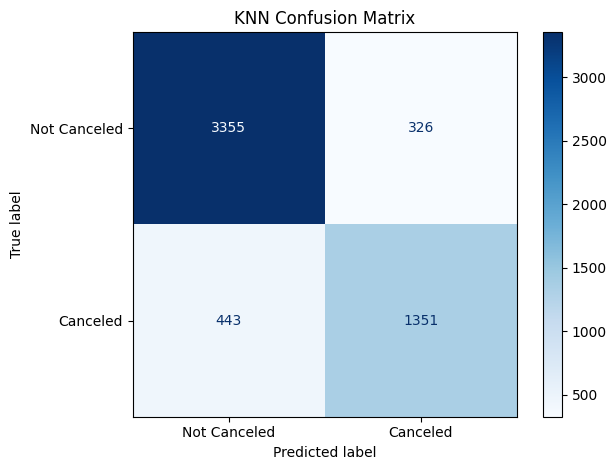

In [240]:
# ==========================================
# K-NEAREST NEIGHBORS (KNN)
# ==========================================

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

print("\n=============================================")
print("K-Nearest Neighbors (KNN)")
print("=============================================\n")

# 1. Memastikan jumlah fitur dan target sesuai
assert len(X_train_prepared) == len(y_train)
assert len(X_val_prepared) == len(y_val)

# 2. Membuat model KNN
knn_model = KNeighborsClassifier(
    n_neighbors=20,
    metric="manhattan",
    weights="distance"
)

# 3. Melatih model menggunakan training data
knn_model.fit(X_train_prepared, y_train)

# 4. Melakukan prediksi pada validation data
y_pred_knn = knn_model.predict(X_val_prepared)

print("Accuracy :", round(accuracy_score(y_val, y_pred_knn), 4))
print("Precision:", round(precision_score(y_val, y_pred_knn, zero_division=0), 4))
print("Recall   :", round(recall_score(y_val, y_pred_knn, zero_division=0), 4))
print("F1-Score :", round(f1_score(y_val, y_pred_knn, zero_division=0), 4))

# 6. Classification Report
print("\nClassification Report:")
print(classification_report(y_val, y_pred_knn, zero_division=0))

# 7. Confusion Matrix
cm = confusion_matrix(y_val, y_pred_knn, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Not Canceled", "Canceled"]
)

disp.plot(cmap="Blues")
plt.title("KNN Confusion Matrix")
plt.tight_layout()
plt.show()

## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

In [228]:
# Write your code here


## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

In [229]:
# Write your code here

## Support Vector Machine

This part covers the linear, polynomial, and Gaussian kernels.

In [230]:
# Write your code here

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

In [231]:
# Write your code here

## Model Evaluation

This part compares the validation results of all models.

In [232]:
# Write your code here

## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

In [233]:
# Write your code here

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [234]:
# Write your code here

---

# Saving and Loading Models <a name="9"></a>

---

This section stores the trained models and restores them for prediction.

In [235]:
# Write your code here

---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [236]:
# Write your code here

---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.